In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [2]:
df = pd.read_csv("supermarket_transactions.csv")
print("Total transactions:", len(df))
print("Missing values:\n", df.isna().sum())
display(df.head(10))

Total transactions: 500
Missing values:
 TransactionID    0
Items            0
dtype: int64


,TransactionID,Items
0,T0001,"Bananas, Biscuits, Bread, Butter, Milk, Tea"
1,T0002,"Biscuits, Bread, Butter, Cereal, Milk, Tea, Yo..."
2,T0003,"Coffee, Eggs, Pasta, Tomato Sauce, Yogurt"
3,T0004,"Apples, Bread, Butter, Eggs, Rice, Sugar"
4,T0005,"Bananas, Biscuits, Bread, Butter, Coffee, Past..."
5,T0006,"Bananas, Bread, Milk, Tea"
6,T0007,"Cereal, Pasta, Rice, Tomato Sauce"
7,T0008,"Apples, Biscuits, Butter, Cheese, Tea, Tomato ..."
8,T0009,"Apples, Biscuits, Cereal, Pasta, Tea, Tomato S..."
9,T0010,"Bananas, Bread, Butter, Cheese, Eggs"


In [3]:
df = df.dropna(subset=["Items"]).drop_duplicates(subset=["TransactionID"])
transactions = [[item.strip() for item in text.split(",") if item.strip()] for text in df["Items"].astype(str)]
te = TransactionEncoder()
encoded = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(encoded, columns=te.columns_)
print("Basket shape:", basket.shape)
display(basket.head())

Basket shape: (500, 16)


,Apples,Bananas,Biscuits,Bread,Butter,Cereal,Cheese,Coffee,Eggs,Milk,Pasta,Rice,Sugar,Tea,Tomato Sauce,Yogurt
0,False,True,True,True,True,False,False,False,False,True,False,False,False,True,False,False
1,False,False,True,True,True,True,False,False,False,True,False,False,False,True,False,True
2,False,False,False,False,False,False,False,True,True,False,True,False,False,False,True,True
3,True,False,False,True,True,False,False,False,True,False,False,True,True,False,False,False
4,False,True,True,True,True,False,False,True,False,False,True,False,False,False,True,False


Butter          278
Bread           275
Tea             215
Biscuits        204
Pasta           198
Tomato Sauce    197
Cereal          194
Milk            183
Bananas         122
Rice            117
dtype: int64


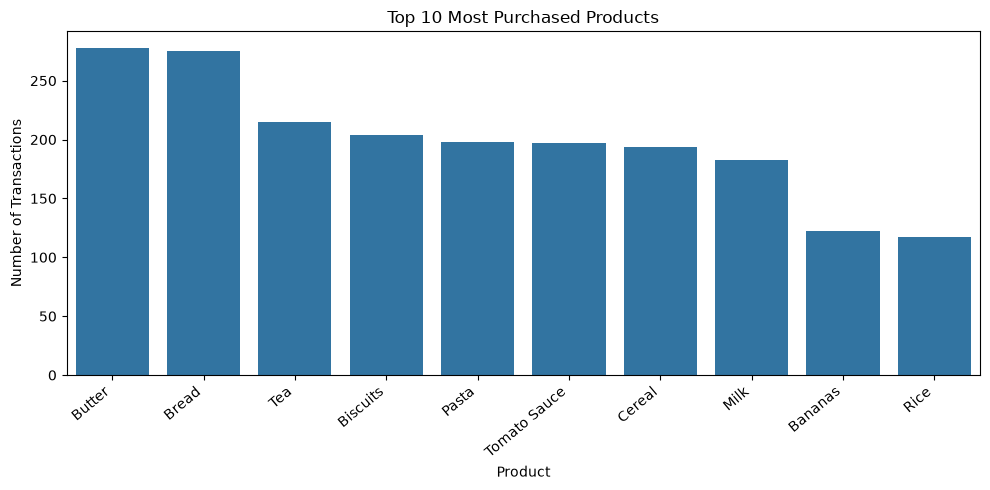

In [4]:
item_counts = basket.sum().sort_values(ascending=False)
print(item_counts.head(10))
plt.figure(figsize=(10,5))
sns.barplot(x=item_counts.head(10).index, y=item_counts.head(10).values)
plt.xticks(rotation=40, ha="right")
plt.title("Top 10 Most Purchased Products")
plt.xlabel("Product")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig("top_products.png", dpi=160)
plt.show()

In [5]:
frequent_itemsets = apriori(basket, min_support=0.05, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False)
print("Frequent itemsets:", len(frequent_itemsets))
display(frequent_itemsets.head(15))

Frequent itemsets: 253


,support,itemsets,length
4,0.556,frozenset({Butter}),1
3,0.550,frozenset({Bread}),1
47,0.438,"frozenset({Bread, Butter})",2
13,0.430,frozenset({Tea}),1
2,0.408,frozenset({Biscuits}),1
10,0.396,frozenset({Pasta}),1
14,0.394,frozenset({Tomato Sauce}),1
5,0.388,frozenset({Cereal}),1
9,0.366,frozenset({Milk}),1
44,0.294,"frozenset({Tea, Biscuits})",2


In [6]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)
rules = rules.sort_values(["lift", "confidence"], ascending=False)
print("Association rules:", len(rules))
display(rules[["antecedents","consequents","support","confidence","lift"]].head(15))

Association rules: 670


,antecedents,consequents,support,confidence,lift
292,"frozenset({Tomato Sauce, Tea})","frozenset({Pasta, Biscuits})",0.076,0.463415,3.174073
295,"frozenset({Pasta, Biscuits})","frozenset({Tomato Sauce, Tea})",0.076,0.520548,3.174073
312,"frozenset({Milk, Biscuits})","frozenset({Tea, Cereal})",0.076,0.506667,3.127572
310,"frozenset({Tea, Cereal})","frozenset({Milk, Biscuits})",0.076,0.469136,3.127572
589,"frozenset({Tea, Milk, Butter})","frozenset({Bread, Biscuits})",0.052,0.634146,2.991256
294,"frozenset({Tea, Pasta})","frozenset({Tomato Sauce, Biscuits})",0.076,0.487179,2.899878
293,"frozenset({Tomato Sauce, Biscuits})","frozenset({Tea, Pasta})",0.076,0.452381,2.899878
313,"frozenset({Cereal, Biscuits})","frozenset({Tea, Milk})",0.076,0.487179,2.865762
309,"frozenset({Tea, Milk})","frozenset({Cereal, Biscuits})",0.076,0.447059,2.865762
591,"frozenset({Milk, Bread, Biscuits})","frozenset({Tea, Butter})",0.052,0.619048,2.839668


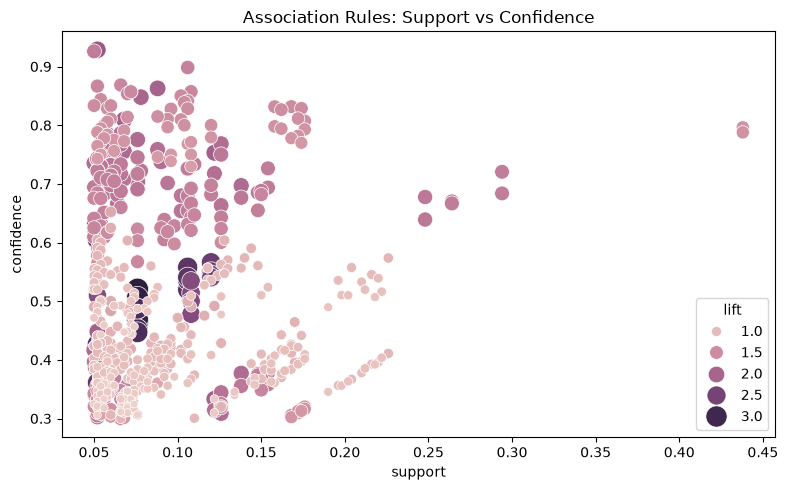

In [7]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=rules, x="support", y="confidence", size="lift", hue="lift", sizes=(30,250))
plt.title("Association Rules: Support vs Confidence")
plt.tight_layout()
plt.savefig("association_rules.png", dpi=160)
plt.show()

In [8]:
def names(x):
    return ", ".join(sorted(x))
for _, rule in rules.head(10).iterrows():
    print(f"If customer buys [{names(rule['antecedents'])}], they may also buy [{names(rule['consequents'])}] | confidence={rule['confidence']:.1%} | lift={rule['lift']:.2f}")

If customer buys [Tea, Tomato Sauce], they may also buy [Biscuits, Pasta] | confidence=46.3% | lift=3.17
If customer buys [Biscuits, Pasta], they may also buy [Tea, Tomato Sauce] | confidence=52.1% | lift=3.17
If customer buys [Biscuits, Milk], they may also buy [Cereal, Tea] | confidence=50.7% | lift=3.13
If customer buys [Cereal, Tea], they may also buy [Biscuits, Milk] | confidence=46.9% | lift=3.13
If customer buys [Butter, Milk, Tea], they may also buy [Biscuits, Bread] | confidence=63.4% | lift=2.99
If customer buys [Pasta, Tea], they may also buy [Biscuits, Tomato Sauce] | confidence=48.7% | lift=2.90
If customer buys [Biscuits, Tomato Sauce], they may also buy [Pasta, Tea] | confidence=45.2% | lift=2.90
If customer buys [Biscuits, Cereal], they may also buy [Milk, Tea] | confidence=48.7% | lift=2.87
If customer buys [Milk, Tea], they may also buy [Biscuits, Cereal] | confidence=44.7% | lift=2.87
If customer buys [Biscuits, Bread, Milk], they may also buy [Butter, Tea] | confide

In [9]:
export_items = frequent_itemsets.copy()
export_items["itemsets"] = export_items["itemsets"].apply(names)
export_items.to_csv("frequent_itemsets.csv", index=False)
export_rules = rules.copy()
export_rules["antecedents"] = export_rules["antecedents"].apply(names)
export_rules["consequents"] = export_rules["consequents"].apply(names)
export_rules.to_csv("association_rules.csv", index=False)
print("Saved frequent_itemsets.csv, association_rules.csv, top_products.png and association_rules.png")

Saved frequent_itemsets.csv, association_rules.csv, top_products.png and association_rules.png
